In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

groq_api_key=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(groq_api_key=groq_api_key,model="openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.13', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7b5e5f1cda90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7b5e5f1ce510>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

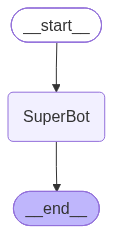

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
# Saves Mem using defaulkt Dict

memory=MemorySaver()

def superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

graph_builder=StateGraph(State)
graph_builder.add_node("SuperBot",superbot)

graph_builder.add_edge(START,"SuperBot")
graph_builder.add_edge("SuperBot",END)

## compile the graph
graph=graph_builder.compile(checkpointer=memory)  #### Added Memory

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
config={"configurable":{"thread_id":"1"}}

In [10]:
graph.invoke({"messages":"Hi, my name is Anas and i like Cricket"},config)

{'messages': [HumanMessage(content='Hi, my name is Anas and i like Cricket', additional_kwargs={}, response_metadata={}, id='6b3416ff-3ed3-487e-a36a-17c10bca81dc'),
  AIMessage(content='Hi Anas! 👋 It’s great to meet a fellow cricket fan. Which team or player do you follow the most? 🎏🏏', additional_kwargs={'reasoning_content': 'User says: "Hi, my name is Anas and i like Cricket". They want a reply. The system says we should comply with user. There\'s no disallowed content. Just a friendly greeting. Let\'s reply warmly.'}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 82, 'total_tokens': 167, 'completion_time': 0.089737237, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.004601455, 'prompt_tokens_details': None, 'queue_time': 0.245853258, 'total_time': 0.094338692}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [14]:
from rich import print

In [15]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph.stream({'messages':"Hi,My name is Anas And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{
    'SuperBot': {
        'messages': [
            AIMessage(
                content='Hey Anas! Glad to hear you’re into cricket. 🎉 Do you have a favorite team, player, or a 
memorable match that you love talking about? Let me know—happy to chat about the game!',
                additional_kwargs={
                    'reasoning_content': "The user repeats the same message. They are greeting and stating they 
like cricket. The user might want a response acknowledging that and maybe ask a question. The assistant should 
respond accordingly. There's no policy violation. Just a friendly reply."
                },
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 100,
                        'prompt_tokens': 147,
                        'total_tokens': 247,
                        'completion_time': 0.108920573,
                        'completion_tokens_details': {'reasoning_tokens': 47},
                        'prompt_time': 0.007032752,
                        'prompt_tokens_details': None,
                        'queue_time': 0.339315345,
                        'total_time': 0.115953325
                    },
                    'model_name': 'openai/gpt-oss-20b',
                    'system_fingerprint': 'fp_9340e7d14d',
                    'service_tier': 'on_demand',
                    'finish_reason': 'stop',
                    'logprobs': None,
                    'model_provider': 'groq'
                },
                id='lc_run--01a1efbe-1be6-7da3-ae72-b9054325ae45-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 147,
                    'output_tokens': 100,
                    'total_tokens': 247,
                    'output_token_details': {'reasoning': 47}
                }
            )
        ]
    }
}

In [17]:
for chunk in graph.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{
    'messages': [
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='78a8d7ba-9f3d-4a02-9b16-ae5a955684d9'
        ),
        AIMessage(
            content='Hello Anas! 👋 It’s great to meet you. Cricket is such a fascinating sport—do you follow any 
particular team or player? Maybe you have a favorite match or memorable moment you’d like to share?',
            additional_kwargs={
                'reasoning_content': 'User says: "Hi,My name is Anas And I like cricket". They are greeting, 
introducing themselves, and expressing interest in cricket. We should respond politely, ask about their interest, 
maybe ask about teams, players. The conversation is open. We should keep friendly.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 110,
                    'prompt_tokens': 82,
                    'total_tokens': 192,
                    'completion_time': 0.111429433,
                    'completion_tokens_details': {'reasoning_tokens': 57},
                    'prompt_time': 0.005141235,
                    'prompt_tokens_details': None,
                    'queue_time': 0.307768071,
                    'total_time': 0.116570668
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_e189667b30',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efbd-ed64-77a3-ac8f-5ecce1841ba0-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 82,
                'output_tokens': 110,
                'total_tokens': 192,
                'output_token_details': {'reasoning': 57}
            }
        ),
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='13f34b23-d6bd-4fc1-b643-6693d24219e4'
        ),
        AIMessage(
            content='Hey Anas! Glad to hear you’re into cricket. 🎉 Do you have a favorite team, player, or a 
memorable match that you love talking about? Let me know—happy to chat about the game!',
            additional_kwargs={
                'reasoning_content': "The user repeats the same message. They are greeting and stating they like 
cricket. The user might want a response acknowledging that and maybe ask a question. The assistant should respond 
accordingly. There's no policy violation. Just a friendly reply."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 100,
                    'prompt_tokens': 147,
                    'total_tokens': 247,
                    'completion_time': 0.108920573,
                    'completion_tokens_details': {'reasoning_tokens': 47},
                    'prompt_time': 0.007032752,
                    'prompt_tokens_details': None,
                    'queue_time': 0.339315345,
                    'total_time': 0.115953325
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_9340e7d14d',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efbe-1be6-7da3-ae72-b9054325ae45-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 147,
                'output_tokens': 100,
                'total_tokens': 247,
                'output_token_details': {'reasoning': 47}
            }
        ),
        HumanMessage(
            content='Hi,My name is Krish And 

{
    'messages': [
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='78a8d7ba-9f3d-4a02-9b16-ae5a955684d9'
        ),
        AIMessage(
            content='Hello Anas! 👋 It’s great to meet you. Cricket is such a fascinating sport—do you follow any 
particular team or player? Maybe you have a favorite match or memorable moment you’d like to share?',
            additional_kwargs={
                'reasoning_content': 'User says: "Hi,My name is Anas And I like cricket". They are greeting, 
introducing themselves, and expressing interest in cricket. We should respond politely, ask about their interest, 
maybe ask about teams, players. The conversation is open. We should keep friendly.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 110,
                    'prompt_tokens': 82,
                    'total_tokens': 192,
                    'completion_time': 0.111429433,
                    'completion_tokens_details': {'reasoning_tokens': 57},
                    'prompt_time': 0.005141235,
                    'prompt_tokens_details': None,
                    'queue_time': 0.307768071,
                    'total_time': 0.116570668
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_e189667b30',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efbd-ed64-77a3-ac8f-5ecce1841ba0-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 82,
                'output_tokens': 110,
                'total_tokens': 192,
                'output_token_details': {'reasoning': 57}
            }
        ),
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='13f34b23-d6bd-4fc1-b643-6693d24219e4'
        ),
        AIMessage(
            content='Hey Anas! Glad to hear you’re into cricket. 🎉 Do you have a favorite team, player, or a 
memorable match that you love talking about? Let me know—happy to chat about the game!',
            additional_kwargs={
                'reasoning_content': "The user repeats the same message. They are greeting and stating they like 
cricket. The user might want a response acknowledging that and maybe ask a question. The assistant should respond 
accordingly. There's no policy violation. Just a friendly reply."
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 100,
                    'prompt_tokens': 147,
                    'total_tokens': 247,
                    'completion_time': 0.108920573,
                    'completion_tokens_details': {'reasoning_tokens': 47},
                    'prompt_time': 0.007032752,
                    'prompt_tokens_details': None,
                    'queue_time': 0.339315345,
                    'total_time': 0.115953325
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_9340e7d14d',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efbe-1be6-7da3-ae72-b9054325ae45-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 147,
                'output_tokens': 100,
                'total_tokens': 247,
                'output_token_details': {'reasoning': 47}
            }
        ),
        HumanMessage(
            content='Hi,My name is Krish And 

In [20]:
# Create a thread
config = {"configurable": {"thread_id": "5"}}

for chunk in graph.stream({'messages':"Hi,My name is Anas And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{
    'SuperBot': {
        'messages': [
            AIMessage(
                content='Hey Anas! 👋 Great to meet you. Cricket’s an awesome sport—whether you’re into the 
fast-paced T20s, the classic Test matches, or the thrilling One-Day Internationals, there’s always something 
exciting happening. What’s your favorite team or player? Or maybe you’d like to chat about a recent match or 
upcoming series? Let me know!',
                additional_kwargs={
                    'reasoning_content': 'The user says: "Hi,My name is Anas And I like cricket". They just 
introduced themselves. They likely want a friendly response. Possibly they want to chat about cricket. Let\'s 
respond in a friendly tone.'
                },
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 130,
                        'prompt_tokens': 82,
                        'total_tokens': 212,
                        'completion_time': 0.153997891,
                        'completion_tokens_details': {'reasoning_tokens': 45},
                        'prompt_time': 0.00457001,
                        'prompt_tokens_details': None,
                        'queue_time': 0.373447249,
                        'total_time': 0.158567901
                    },
                    'model_name': 'openai/gpt-oss-20b',
                    'system_fingerprint': 'fp_e23fc997ca',
                    'service_tier': 'on_demand',
                    'finish_reason': 'stop',
                    'logprobs': None,
                    'model_provider': 'groq'
                },
                id='lc_run--01a1efc4-0297-7841-9d18-ff555da75b49-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 82,
                    'output_tokens': 130,
                    'total_tokens': 212,
                    'output_token_details': {'reasoning': 45}
                }
            )
        ]
    }
}

In [21]:
for chunk in graph.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{
    'messages': [
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='49fafb7d-cf40-4be5-bbe5-fa5ce83547ad'
        ),
        AIMessage(
            content='Hey Anas! 👋 Great to meet you. Cricket’s an awesome sport—whether you’re into the fast-paced 
T20s, the classic Test matches, or the thrilling One-Day Internationals, there’s always something exciting 
happening. What’s your favorite team or player? Or maybe you’d like to chat about a recent match or upcoming 
series? Let me know!',
            additional_kwargs={
                'reasoning_content': 'The user says: "Hi,My name is Anas And I like cricket". They just introduced 
themselves. They likely want a friendly response. Possibly they want to chat about cricket. Let\'s respond in a 
friendly tone.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 130,
                    'prompt_tokens': 82,
                    'total_tokens': 212,
                    'completion_time': 0.153997891,
                    'completion_tokens_details': {'reasoning_tokens': 45},
                    'prompt_time': 0.00457001,
                    'prompt_tokens_details': None,
                    'queue_time': 0.373447249,
                    'total_time': 0.158567901
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_e23fc997ca',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efc4-0297-7841-9d18-ff555da75b49-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 82,
                'output_tokens': 130,
                'total_tokens': 212,
                'output_token_details': {'reasoning': 45}
            }
        ),
        HumanMessage(
            content='I also like football',
            additional_kwargs={},
            response_metadata={},
            id='e68926be-f52b-42ab-808d-26ab65b42d8f'
        )
    ]
}

{
    'messages': [
        HumanMessage(
            content='Hi,My name is Anas And I like cricket',
            additional_kwargs={},
            response_metadata={},
            id='49fafb7d-cf40-4be5-bbe5-fa5ce83547ad'
        ),
        AIMessage(
            content='Hey Anas! 👋 Great to meet you. Cricket’s an awesome sport—whether you’re into the fast-paced 
T20s, the classic Test matches, or the thrilling One-Day Internationals, there’s always something exciting 
happening. What’s your favorite team or player? Or maybe you’d like to chat about a recent match or upcoming 
series? Let me know!',
            additional_kwargs={
                'reasoning_content': 'The user says: "Hi,My name is Anas And I like cricket". They just introduced 
themselves. They likely want a friendly response. Possibly they want to chat about cricket. Let\'s respond in a 
friendly tone.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 130,
                    'prompt_tokens': 82,
                    'total_tokens': 212,
                    'completion_time': 0.153997891,
                    'completion_tokens_details': {'reasoning_tokens': 45},
                    'prompt_time': 0.00457001,
                    'prompt_tokens_details': None,
                    'queue_time': 0.373447249,
                    'total_time': 0.158567901
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_e23fc997ca',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
            id='lc_run--01a1efc4-0297-7841-9d18-ff555da75b49-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 82,
                'output_tokens': 130,
                'total_tokens': 212,
                'output_token_details': {'reasoning': 45}
            }
        ),
        HumanMessage(
            content='I also like football',
            additional_kwargs={},
            response_metadata={},
            id='e68926be-f52b-42ab-808d-26ab65b42d8f'
        ),
        AIMessage(
            content='That’s awesome! 🎉 Cricket and football are both huge—each with its own style, drama, and 
passionate fan base. Whether you’re cheering for a thrilling last‑over finish on the cricket pitch or rooting for a
nail‑biter in the 90th minute on the football field, there’s always something to talk about.\n\n- **Cricket**: Any 
particular formats you love (T20, ODI, Test) or teams you follow?  \n- **Football**: Are you into the Premier 
League, La Liga, Serie A, or maybe international tournaments like the World Cup or Euros?  \n\nLet me know which 
one (or both) you’d like to dive into—whether it’s recent matches, player stats, or just fun trivia. I’m all 
ears!',
            additional_kwargs={
                'reasoning_content': 'User says they like football as well. We should respond in friendly tone, 
acknowledging both sports. Offer to discuss either.'
            },
            response_metadata={
                'token_usage': {
                    'completion_tokens': 192,
                    'prompt_tokens': 172,
                    'total_tokens': 364,
                    'completion_time': 0.209712221,
                    'completion_tokens_details': {'reasoning_tokens': 25},
                    'prompt_time': 0.009714326,
                    'prompt_tokens_details': None,
                    'queue_time': 0.340016131,
                    'total_time': 0.219426547
                },
                'model_name': 'openai/gpt-oss-20b',
                'system_fingerprint': 'fp_d3e146e1a5',
                'service_tier': 'on_demand',
                'finish_reason': 'stop',
                'logprobs': None,
                'model_provider': 'groq'
            },
  

In [11]:
config = {"configurable": {"thread_id": "6"}}

async for event in graph.astream_events({"messages":["Hi My name is Anas and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Anas and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1efc7-76fa-7383-a0a1-50119c8e9283', 'metadata': {'thread_id': '6', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Anas and I like to play cricket', additional_kwargs={}, response_metadata={}, id='3329b574-4deb-4c6c-9eca-9bc3b780a543')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1efc7-7701-7eb2-9515-1edab7468a05', 'metadata': {'thread_id': '6', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:43f12af3-bf25-d66a-6fac-66727a95b68a'}, 'parent_ids': ['01a1efc7-76fa-7383-a0a1-50119c8e9283']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [